In [ ]:
# First attempt at implementing logistic regression.
# We want to:
#   - Load the data, split into training and test set
#   - Set the hyperparameters, which should now include regularization as well as normalization 
#   - Define functions for the Cost function and the gradient
#   - some basic plotting 

# # Datasets from the course, they have the following descriptions:
# Dataset 1:
# Suppose that you are the administrator of a university department and you want to determine each applicant’s chance of 
# admission based on their results on two exams.

# You have historical data from previous applicants that you can use as a training set for logistic regression.
# For each training example, you have the applicant’s scores on two exams and the admissions decision.
# Your task is to build a classification model that estimates an applicant’s probability of admission based on the scores 
# from those two exams.

# Dataset 2:
# Suppose you are the product manager of the factory and you have the test results for some microchips on two different tests.

# From these two tests, you would like to determine whether the microchips should be accepted or rejected.
# To help you make the decision, you have a dataset of test results on past microchips, from which you can build a 
# logistic regression model.

# This notebook uses Dataset 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('fivethirtyeight')
rng = np.random.default_rng(seed=67)

In [54]:
# Load data:
data = np.loadtxt("ex2data1.txt", delimiter=",")
print(data[:5], len(data))

#let's split a training and a testing set 90/10
rng.shuffle(data)
split = (len(data) * 9) // 10
x_train_raw = data[:split,:-1]
y_train = data[:split,-1]
x_test = data[split:,:-1]
y_test = data[split:,-1]

[[34.62365962 78.02469282  0.        ]
 [30.28671077 43.89499752  0.        ]
 [35.84740877 72.90219803  0.        ]
 [60.18259939 86.3085521   1.        ]
 [79.03273605 75.34437644  1.        ]] 100


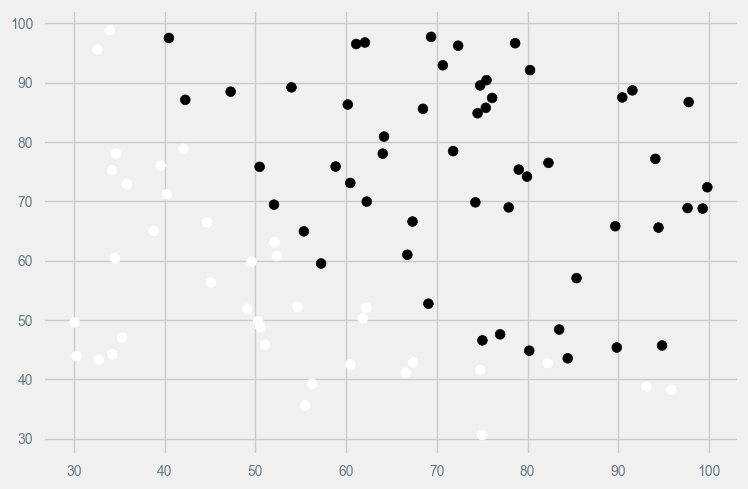

In [55]:
# Some pre-normalisation plotting
plt.scatter(x_train_raw[:,0],x_train_raw[:,1], c=y_train)

In [56]:
# Defining features:

def select_features(x):
    #Feature construction:
    # x_squ = x_train_raw ** 2
    x0_mul_x1 = x[:,0] * x[:,1]
    return np.column_stack((x,x0_mul_x1))

    #return x.copy() # no change in features

x_train = select_features(x_train_raw)
print(x_train_raw.shape)
print(x_train.shape)

(90, 2)
(90, 3)


In [57]:
# Z-normalisation:
z_norm = True
if z_norm:
    x_mean = np.mean(x_train, axis=0)
    x_std = x_train.std(axis=0)
    x_train -= x_mean
    x_train /= x_std
    # print(f"{np.ptp(x_train, axis=0)=} {np.mean(x_train, axis=0)=}")
    # print(f"{np.ptp(x_train, axis=0)=} {np.mean(x_train, axis=0)=}")
    # plt.scatter(x_train[:,2],y_train)


In [59]:
#Set Hyperparameters:
learning_rate = 0.01
iterations = 250000
#batch_size = 100
lam = 0.001  # regularization parameter

In [60]:
# Initialization:
m = len(x_train)    # number of rows in training set (= number of examples)
n = len(x_train[0]) # number of columns in training set (= number of features)
w = np.zeros(n)
b = 0
loss_history = []

In [ ]:
def calc_f_x(x, w, b):
    """
    z = w dot x + b
    f_x = sigmoid(z)
    """
    z = x @ w + b
    f_x = 1 / (1 + np.e ** -z)
    #print(z)
    return f_x

def calc_cost(f_x_passed, y, w):
    f_x = np.where(y == 1, f_x_passed, 1 - f_x_passed)
    loss = -1 * np.log(f_x)
    reg_pen = lam / (2 * m) * np.sum(w ** 2)
    return loss.sum() / m + reg_pen

def gradient(x, f_x, y, w):
    norm_err = (f_x - y) / m
    #print(f'{f_x.shape=}, {y.shape=}, {norm_err.shape=}')
    gradient_b = norm_err.sum()
    gradient_w = x.T @ norm_err
    gradient_w += lam / m * w
    # gradient_w[0]=gradient_w[1]=0
    return gradient_w, gradient_b

def predict(x_in,w,b):
    x = select_features(x_in)
    if z_norm:
        x -= x_mean
        x /= x_std
    f_x = calc_f_x(x,w,b)
    return np.round(f_x)


In [61]:
for iteration in range(iterations):
    f_x = calc_f_x(x_train, w, b)
    gradient_w, gradient_b = gradient(x_train, f_x, y_train, w)
    w -= learning_rate * gradient_w
    b -= learning_rate * gradient_b
    loss_history.append(calc_cost(f_x, y_train, w))
    # print(loss_history[-1],gradient_w,gradient_b,w,b)



0.08313403210744191, [-1.82941988 -1.39130393 15.02917459], 6.150420255846177


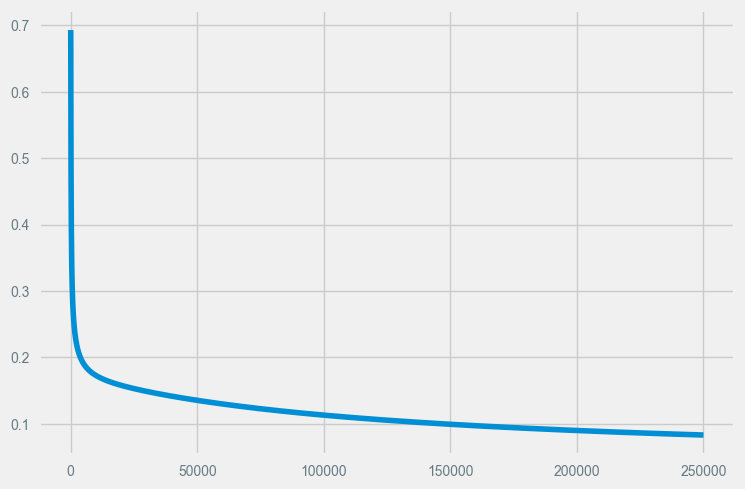

In [62]:
print(f'{loss_history[-1]}, {w}, {b}')
plt.plot(loss_history)

In [63]:
f_x_test = predict(x_test, w, b)
for i in range(len(f_x_test)):
    print (f"{f_x_test[i]}, {y_test[i]}")

1.0, 1.0
1.0, 1.0
0.0, 0.0
0.0, 0.0
1.0, 1.0
1.0, 1.0
1.0, 1.0
1.0, 1.0
0.0, 0.0
1.0, 1.0


In [64]:
f_x_train = predict(x_train_raw, w, b)
no_c = no_f = 0
for i in range(len(f_x_train)):
    if f_x_train[i] == y_train[i]: no_c += 1
    else: no_f += 1
    # print (f"{f_x_train[i]}, {y_train[i]}")
print(f"{no_c=}, {no_f=}")

no_c=88, no_f=2


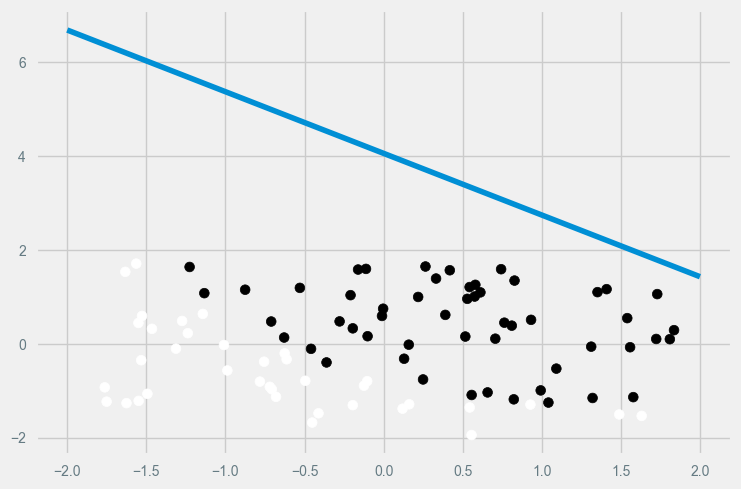

In [65]:
#For two features:
x0_line = np.arange(-2,3)
x1_line = (0.5 - b - w[0] * x0_line) / w[1]
plt.plot(x0_line, x1_line)
plt.scatter(x_train[:,0],x_train[:,1], c=y_train)

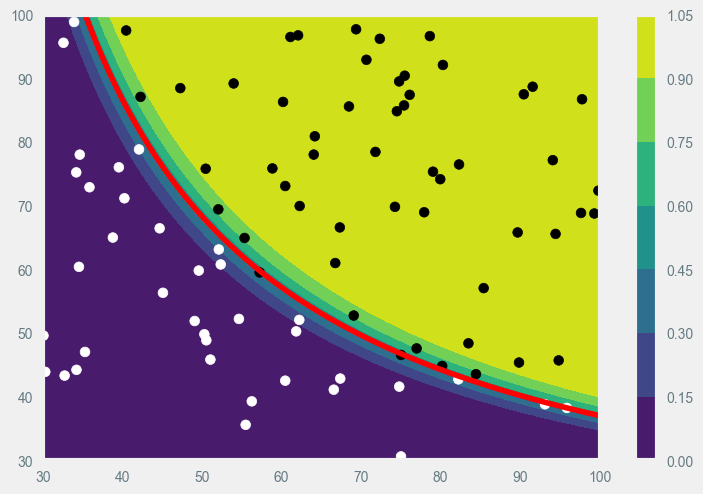

In [66]:
# For engineered features x0, x1, x0 * x1

x0_grid = np.linspace(30, 100, 100)
x1_grid = np.linspace(30, 100, 100)
X0_mesh, X1_mesh = np.meshgrid(x0_grid, x1_grid)

# Normalize each feature using training statistics
X0_norm = (X0_mesh - x_mean[0]) / x_std[0]
X1_norm = (X1_mesh - x_mean[1]) / x_std[1]
Interaction_norm = (X0_mesh * X1_mesh - x_mean[2]) / x_std[2]  # Key: normalize the product!

# Apply model with original weights
Z_linear = w[0]*X0_norm + w[1]*X1_norm + w[2]*Interaction_norm + b
Z = 1 / (1 + np.e ** (-Z_linear))

plt.contourf(X0_mesh, X1_mesh, Z, cmap='viridis')
plt.colorbar()
plt.scatter(x_train_raw[:,0], x_train_raw[:,1], c=y_train)
plt.contour(X0_mesh, X1_mesh, Z, levels=[0.5], colors='r')


Unnormalized equation: 0.008381*x0*x1 + -0.094364*x0 + -0.074491*x1 + -18.823743 = 0


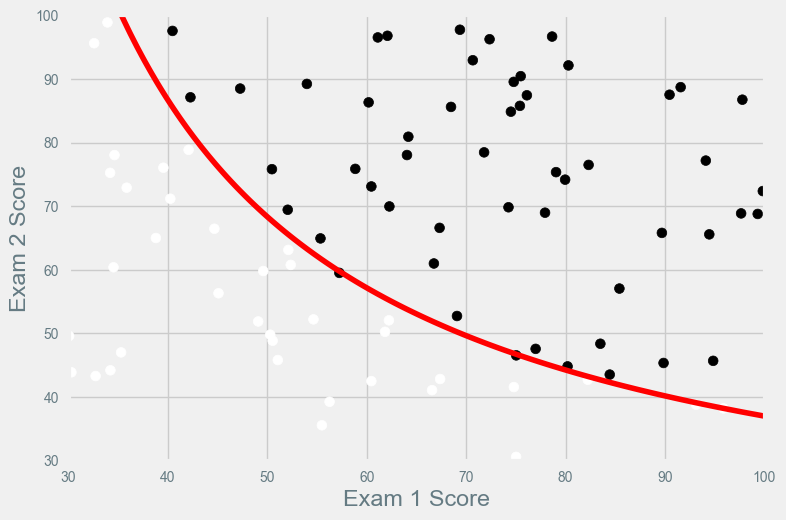

In [67]:
# Equivalent, Unnormalize the equation completely
a = w[2] / x_std[2]
b_coef = w[0] / x_std[0]
c_coef = w[1] / x_std[1]
d = b - (w[0]*x_mean[0]/x_std[0]) - (w[1]*x_mean[1]/x_std[1]) - (w[2]*x_mean[2]/x_std[2])

print(f"Unnormalized equation: {a:.6f}*x0*x1 + {b_coef:.6f}*x0 + {c_coef:.6f}*x1 + {d:.6f} = 0")

# Plot in raw space
x0_grid = np.linspace(30, 100, 100)
x1_grid = np.linspace(30, 100, 100)
X0_mesh, X1_mesh = np.meshgrid(x0_grid, x1_grid)

Z_raw = a*X0_mesh*X1_mesh + b_coef*X0_mesh + c_coef*X1_mesh + d
Z = 1 / (1 + np.e ** (-Z_raw))

plt.scatter(x_train_raw[:,0], x_train_raw[:,1], c=y_train)
plt.contour(X0_mesh, X1_mesh, Z, levels=[0.5], colors='r')
plt.xlabel('Exam 1 Score')
plt.ylabel('Exam 2 Score')
plt.show()